# Proyecto de Ciencia de Datos: exoplanetas de la misión Kepler
## Notebook 1 · Presentación y exploración del dataset

**Autor:** Jheison Martinez Bolivar · **Asignatura:** Ciencia de Datos · **Fecha:** octubre de 2026

Este es el dataset con el que trabajaré durante la asignatura: el **catálogo KOI de la misión Kepler**, con miles de señales de posibles exoplanetas. La pregunta de fondo del proyecto es **¿se puede predecir si una señal corresponde a un planeta real o a un falso positivo?**

En este primer cuaderno el objetivo es solo **conocer el dataset**: de dónde viene, qué columnas tiene, cómo es la variable objetivo, qué calidad tienen los datos y qué patrones se ven a simple vista.


## 1. Contexto y entorno

**Kepler** (NASA, 2009–2013) vigiló unas 150 000 estrellas buscando pequeñas caídas periódicas de brillo, que es lo que ocurre cuando un planeta pasa por delante de su estrella (Borucki et al., 2010). Cada señal sospechosa se registra como un **KOI** (*Kepler Object of Interest*) y pasa por un proceso de verificación, automatizado por el **Robovetter** (Thompson et al., 2018). Muchas señales resultan ser **falsos positivos**: binarias eclipsantes, estrellas de fondo cuya luz se mezcla con la del objetivo, o ruido instrumental.

Los datos vienen de la tabla *KOI Cumulative* del NASA Exoplanet Archive (Akeson et al., 2013), servida mediante su API TAP. La celda siguiente prepara el entorno; si falta alguna librería, descomenta la línea `%pip`.

In [1]:
# %pip install "pandas>=2.1" numpy matplotlib seaborn scipy requests pyarrow
import hashlib
import json
import re
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
RAW_PATH = DATA_DIR / "koi_cumulative_raw.csv"
META_PATH = DATA_DIR / "koi_cumulative_meta.json"
TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
CONSULTA = "select * from cumulative"
FORZAR_DESCARGA = False  # True = volver a descargar aunque exista la copia local

# Clases y colores fijos en todo el cuaderno (paleta validada para daltonismo)
CONF, CAND, FP = "CONFIRMED", "CANDIDATE", "FALSE POSITIVE"
ORDEN_CLASES = [CONF, FP, CAND]
COLORES = {CONF: "#2a78d6", FP: "#eb6834", CAND: "#1baf7a"}
ETIQUETA = {CONF: "Confirmado", FP: "Falso positivo", CAND: "Candidato"}
GRIS = "#8a8984"

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "grid.alpha": 0.35})
pd.set_option("display.max_columns", 40)


def md(texto: str) -> None:
    """Muestra texto Markdown generado a partir de los resultados."""
    display(Markdown(texto))


def pct(x: float) -> str:
    return f"{100 * x:.1f} %"

## 2. Adquisición de los datos

Se piden **todas las columnas** porque decidir cuáles sirven es justamente el objetivo del EDA. Para que el análisis sea reproducible, la descarga se guarda en `data/` junto con su fecha y su huella SHA-256, y las siguientes ejecuciones reutilizan esa copia. `koi_quarters` se fuerza a texto porque es una cadena de 32 bits (un bit por trimestre observado) que pandas convertiría en un entero gigante.

In [2]:
def sha256(ruta: Path) -> str:
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


if FORZAR_DESCARGA or not RAW_PATH.exists():
    try:
        r = requests.get(TAP_URL, params={"query": CONSULTA, "format": "csv"}, timeout=180)
        r.raise_for_status()
        if r.content.lstrip()[:1] == b"<":  # el servicio devuelve XML cuando la consulta falla
            raise ValueError(r.content[:300])
        RAW_PATH.write_bytes(r.content)
        META_PATH.write_text(json.dumps({
            "url": TAP_URL, "consulta": CONSULTA, "sha256": sha256(RAW_PATH),
            "fecha_descarga_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}, indent=2))
    except Exception as e:
        if not RAW_PATH.exists():
            raise RuntimeError(f"No se pudo descargar el catálogo y no hay copia local: {e}") from e
        print(f"Aviso: la descarga falló ({type(e).__name__}); se usa la copia local.")

meta = (json.loads(META_PATH.read_text()) if META_PATH.exists()
        else {"fecha_descarga_utc": "desconocida", "sha256": sha256(RAW_PATH)})
df = pd.read_csv(RAW_PATH, low_memory=False,
                 dtype={"koi_quarters": str, "kepoi_name": str, "kepler_name": str})

n_filas, n_cols = df.shape
print(f"Fecha de descarga: {meta['fecha_descarga_utc']} · SHA-256: {meta['sha256'][:12]}…")
print(f"{n_filas:,} KOI × {n_cols} columnas · {df['kepid'].nunique():,} estrellas · "
      f"{int(df.duplicated().sum())} filas duplicadas · {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Fecha de descarga: 2026-11-08T19:18:22+00:00 · SHA-256: a85348f20082…
9,564 KOI × 153 columnas · 8,214 estrellas · 0 filas duplicadas · 24.6 MB


### 2.1 Mapa de columnas

Con más de cien columnas conviene agruparlas por su origen antes de mirarlas. La agrupación usa los prefijos documentados por el Exoplanet Archive. Dos grupos merecen atención especial: las **incertidumbres** (`_err1`/`_err2`), que multiplican el número de columnas sin añadir variables nuevas, y **«Disposición / vetting»**, que contiene las salidas del proceso que genera la etiqueta y es el primer sospechoso de fuga.

In [3]:
GRUPOS = [  # el orden importa: gana la primera coincidencia
    ("Incertidumbre", r"_err[12]?$"),
    ("Identificación y posición", r"^(kepid|kepoi_name|kepler_name|ra|dec|ra_str|dec_str|rowid)$"),
    ("Disposición / vetting", r"^koi_(disposition|pdisposition|score|fpflag_\w+|vet_stat|vet_date|disp_prov|comment)$"),
    ("Ajuste del tránsito", r"^koi_(period|time0bk|time0|eccen|longp|impact|duration|ingress|depth|ror|srho|fittype|incl|dor|ldm_coeff\d|limbdark_mod|trans_mod|model_dof|model_chisq)$"),
    ("Planeta (derivado)", r"^koi_(prad|sma|teq|insol)$"),
    ("Detección (pipeline)", r"^koi_(max_sngle_ev|max_mult_ev|model_snr|count|num_transits|tce_plnt_num|tce_delivname|quarters|bin_oedp_sig)$"),
    ("Estrella anfitriona", r"^koi_(steff|slogg|smet|srad|smass|sage|sparprov)$"),
    ("Fotometría", r"^koi_(kepmag|[grizjhk]mag)$"),
    ("Centroides", r"^koi_(fwm_|dicco_|dikco_)"),
    ("Procedencia y enlaces", r"^koi_(parm_prov|datalink_\w+)$"),
]


def grupo_de(col: str) -> str:
    return next((nombre for nombre, patron in GRUPOS if re.search(patron, col)), "Otros")


mapa = pd.DataFrame({"columna": df.columns, "grupo": [grupo_de(c) for c in df.columns],
                     "pct_nulos": df.isna().mean().values})
(mapa.groupby("grupo")
     .agg(n_columnas=("columna", "size"), nulos_medios=("pct_nulos", "mean"),
          ejemplos=("columna", lambda s: ", ".join(s.head(4))))
     .sort_values("n_columnas", ascending=False)
     .assign(nulos_medios=lambda t: t["nulos_medios"].map(pct)))

,n_columnas,nulos_medios,ejemplos
grupo,,,
Incertidumbre,68,31.2 %,"ra_err, dec_err, koi_gmag_err, koi_rmag_err"
Ajuste del tránsito,22,20.4 %,"koi_limbdark_mod, koi_ldm_coeff4, koi_ldm_coef..."
Centroides,13,6.6 %,"koi_fwm_stat_sig, koi_fwm_sra, koi_fwm_sdec, k..."
Disposición / vetting,11,2.6 %,"koi_vet_stat, koi_disposition, koi_pdispositio..."
Detección (pipeline),9,8.3 %,"koi_quarters, koi_count, koi_num_transits, koi..."
Fotometría,8,1.2 %,"koi_gmag, koi_rmag, koi_imag, koi_zmag"
Estrella anfitriona,7,17.6 %,"koi_steff, koi_slogg, koi_smet, koi_srad"
Identificación y posición,7,10.2 %,"kepid, kepoi_name, kepler_name, ra"
Planeta (derivado),4,3.7 %,"koi_prad, koi_sma, koi_teq, koi_insol"


## 3. Variable objetivo

Hay dos columnas de disposición. `koi_pdisposition` usa **solo** los datos de Kepler (CANDIDATE o FALSE POSITIVE), mientras que `koi_disposition` incorpora además confirmaciones publicadas en la literatura (CONFIRMED, CANDIDATE o FALSE POSITIVE). La variable objetivo será `koi_disposition`. Para el modelo se usará como etiqueta binaria `es_planeta` (1 = confirmado, 0 = falso positivo); los **candidatos** quedan aparte, porque son precisamente los casos que el modelo intentará clasificar al final.

/tmp/ipykernel_2597136/2682551488.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["es_planeta"] = df["koi_disposition"].map({CONF: 1, FP: 0})  # CANDIDATE -> NaN


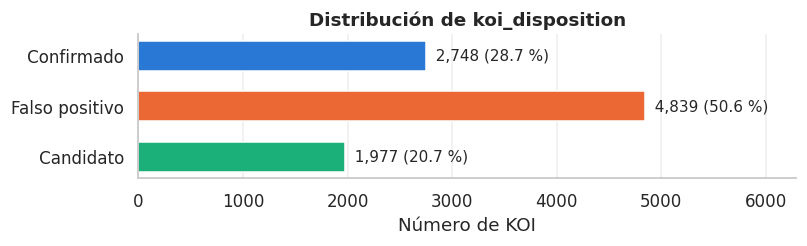

**Lectura.** Hay **7,587 KOI con etiqueta** (confirmados + falsos positivos), de los cuales el 36.2 % son planetas, y **1,977 candidatos** sin resolver. Las clases no están equilibradas, algo a tener en cuenta al modelar.

In [4]:
df["es_planeta"] = df["koi_disposition"].map({CONF: 1, FP: 0})  # CANDIDATE -> NaN
etiquetados = df["es_planeta"].notna()
lab, y_lab = df[etiquetados], df.loc[etiquetados, "es_planeta"]
conteo = df["koi_disposition"].value_counts().reindex(ORDEN_CLASES).fillna(0).astype(int)
prop = conteo / conteo.sum()

fig, ax = plt.subplots(figsize=(7.5, 2.4))
ax.barh([ETIQUETA[c] for c in conteo.index[::-1]], conteo.values[::-1],
        color=[COLORES[c] for c in conteo.index[::-1]], height=0.6)
for y, (n, p) in enumerate(zip(conteo.values[::-1], prop.values[::-1])):
    ax.text(n, y, f"  {n:,} ({pct(p)})", va="center", fontsize=10)
ax.set_xlim(0, conteo.max() * 1.3)
ax.set_xlabel("Número de KOI")
ax.set_title("Distribución de koi_disposition")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

frac_pos = y_lab.mean()
md(f"""**Lectura.** Hay **{len(lab):,} KOI con etiqueta** (confirmados + falsos positivos), de los cuales el {pct(frac_pos)} son planetas, \
y **{conteo[CAND]:,} candidatos** sin resolver. {"Las clases no están equilibradas, algo a tener en cuenta al modelar." if min(frac_pos, 1 - frac_pos) < 0.4 else "Las clases están razonablemente equilibradas."}""")

## 4. Ficha de las variables principales

De las más de cien columnas, estas son las que describen físicamente cada señal. La tabla resume para qué sirve cada una y sus valores típicos (mediana y rango entre los percentiles 1 y 99, para que los valores extremos no distorsionen la imagen).

In [5]:
VARIABLES = {
    "koi_period": ("Tránsito", "Periodo orbital", "días"),
    "koi_duration": ("Tránsito", "Duración del tránsito", "horas"),
    "koi_depth": ("Tránsito", "Profundidad: cuánto baja el brillo", "ppm"),
    "koi_impact": ("Tránsito", "Parámetro de impacto (0 = cruza por el centro, >1 = rasante)", "—"),
    "koi_model_snr": ("Detección", "Relación señal/ruido del tránsito", "—"),
    "koi_count": ("Detección", "Número de señales en la misma estrella", "—"),
    "koi_prad": ("Planeta", "Radio del planeta", "R⊕"),
    "koi_teq": ("Planeta", "Temperatura de equilibrio", "K"),
    "koi_insol": ("Planeta", "Radiación recibida respecto a la Tierra", "S⊕"),
    "koi_steff": ("Estrella", "Temperatura de la estrella", "K"),
    "koi_srad": ("Estrella", "Radio de la estrella", "R☉"),
    "koi_slogg": ("Estrella", "Gravedad superficial (log g)", "cgs"),
    "koi_kepmag": ("Estrella", "Brillo aparente en la banda de Kepler", "mag"),
}
VARIABLES = {k: v for k, v in VARIABLES.items() if k in df.columns}
ficha = pd.DataFrame(VARIABLES, index=["grupo", "descripción", "unidad"]).T
q = df[list(VARIABLES)].quantile([0.01, 0.5, 0.99]).T
ficha["mediana"] = q[0.5].round(2)
ficha["rango típico (p1–p99)"] = [f"{a:,.2f} – {b:,.2f}" for a, b in zip(q[0.01], q[0.99])]
ficha["% nulos"] = df[list(VARIABLES)].isna().mean().map(pct)
ficha

,grupo,descripción,unidad,mediana,rango típico (p1–p99),% nulos
koi_period,Tránsito,Periodo orbital,días,9.75,0.53 – 551.00,0.0 %
koi_duration,Tránsito,Duración del tránsito,horas,3.79,0.80 – 30.05,0.0 %
koi_depth,Tránsito,Profundidad: cuánto baja el brillo,ppm,421.10,"24.10 – 416,737.00",3.8 %
koi_impact,Tránsito,"Parámetro de impacto (0 = cruza por el centro,...",—,0.54,0.00 – 1.78,3.8 %
koi_model_snr,Detección,Relación señal/ruido del tránsito,—,23.00,"5.00 – 4,355.50",3.8 %
koi_count,Detección,Número de señales en la misma estrella,—,1.00,1.00 – 5.00,0.0 %
koi_prad,Planeta,Radio del planeta,R⊕,2.39,0.52 – 369.20,3.8 %
koi_teq,Planeta,Temperatura de equilibrio,K,878.00,"196.00 – 4,106.00",3.8 %
koi_insol,Planeta,Radiación recibida respecto a la Tierra,S⊕,141.60,"0.35 – 70,297.16",3.4 %
koi_steff,Estrella,Temperatura de la estrella,K,5767.00,"3,638.00 – 8,144.00",3.8 %


## 5. Calidad de los datos

Un vistazo rápido a los problemas habituales: columnas vacías o que siempre valen lo mismo (no aportan nada) y columnas con valores faltantes.

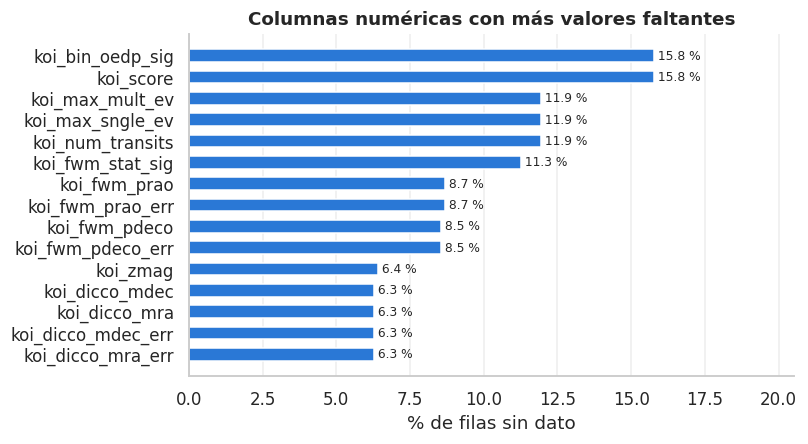

**Lectura.** Hay **24 columnas vacías** (`koi_gmag_err`, `koi_rmag_err`, `koi_imag_err`, `koi_zmag_err`, `koi_kepmag_err`, `koi_model_dof`, `koi_model_chisq`, `koi_eccen_err1`, `koi_eccen_err2`, `koi_longp`, `koi_longp_err1`, `koi_longp_err2`, `koi_sma_err1`, `koi_sma_err2`, `koi_ingress`, `koi_ingress_err1`, `koi_ingress_err2`, `koi_incl_err1`, `koi_incl_err2`, `koi_teq_err1`, `koi_teq_err2`, `koi_sage`, `koi_sage_err1`, `koi_sage_err2`) y **11 constantes**, que se pueden descartar. Entre las demás columnas numéricas (sin contar incertidumbres), la que más datos le faltan es `koi_bin_oedp_sig` con un 15.8 %; en general el dataset está **bastante completo**. No hay filas duplicadas.

In [6]:
nulos = df.isna().mean()
cols_vacias = nulos[nulos == 1].index.tolist()
cols_constantes = [c for c in df.columns if c not in cols_vacias and df[c].nunique(dropna=True) <= 1]
num = df.select_dtypes("number").drop(columns="es_planeta")
nulos_num = nulos[num.columns].drop(index=cols_vacias, errors="ignore")
nulos_num = nulos_num[(nulos_num > 0) & ~nulos_num.index.str.contains(r"_err[12]$")].sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7.5, max(2.5, 0.28 * len(nulos_num))))
ax.barh(nulos_num.index[::-1], nulos_num.values[::-1] * 100, color=COLORES[CONF], height=0.6)
for y, v in enumerate(nulos_num.values[::-1]):
    ax.text(v * 100, y, f" {v * 100:.1f} %", va="center", fontsize=8)
ax.set_xlim(0, max(5, nulos_num.max() * 130))
ax.set_xlabel("% de filas sin dato")
ax.set_title("Columnas numéricas con más valores faltantes")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** Hay **{len(cols_vacias)} columnas vacías** ({", ".join(f"`{c}`" for c in cols_vacias) or "ninguna"}) \
y **{len(cols_constantes)} constantes**, que se pueden descartar. Entre las demás columnas numéricas (sin contar incertidumbres), \
la que más datos le faltan es `{nulos_num.index[0]}` con un {pct(nulos_num.iloc[0])}\
{"; en general el dataset está **bastante completo**" if nulos_num.iloc[0] < 0.3 else ", así que habrá que decidir cómo tratar los faltantes"}. \
{"No hay filas duplicadas." if not df.duplicated().any() else f"Hay {int(df.duplicated().sum())} filas duplicadas."}""")

## 6. ¿En qué se diferencian los planetas de los falsos positivos?

Cada panel compara la distribución de una variable en las tres clases. Varias variables abarcan varios órdenes de magnitud (hay periodos de horas y de cientos de días), así que se muestran en escala logarítmica. Lo interesante es dónde las curvas azul (confirmados) y naranja (falsos positivos) **no se solapan**.

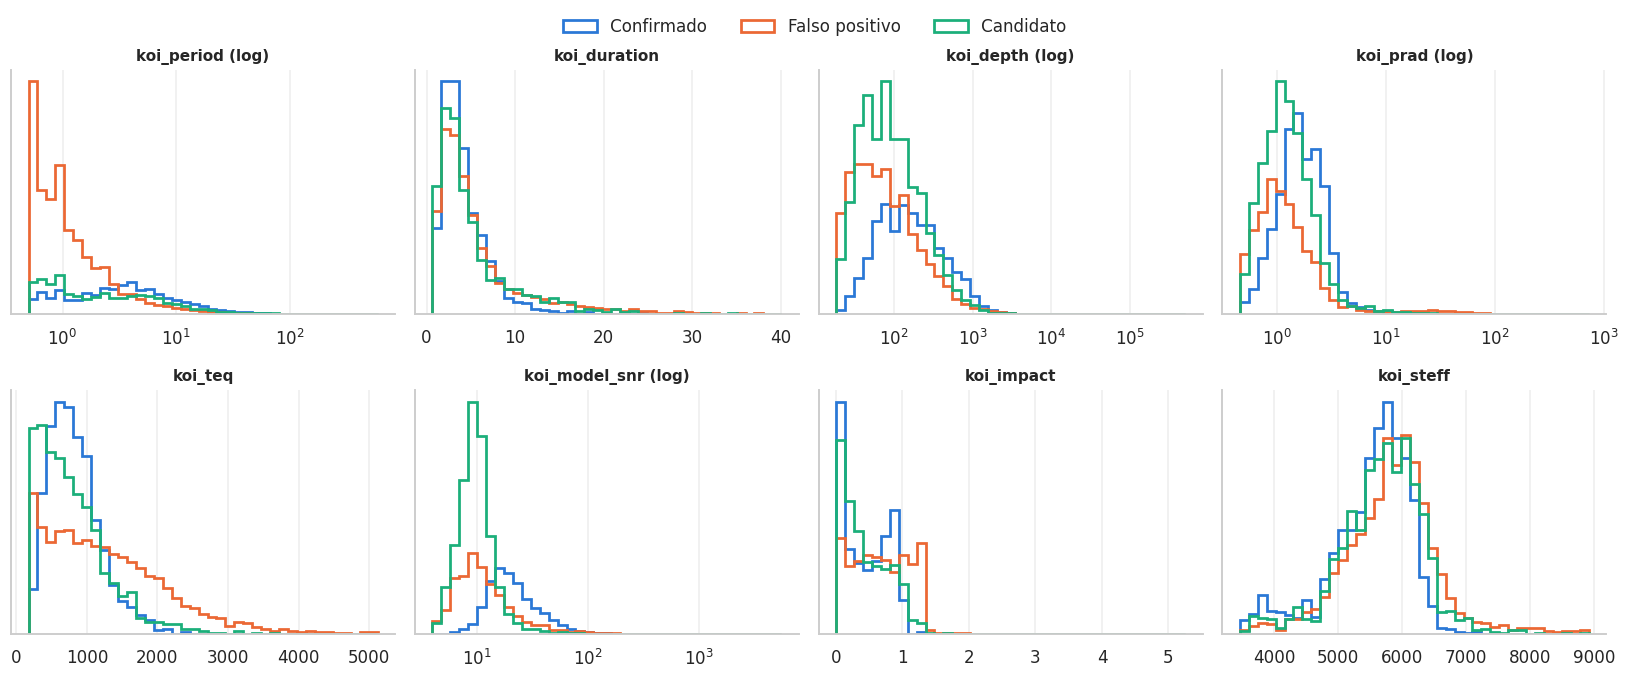

**Lectura.** La mediana de la profundidad es 576 ppm en los falsos positivos frente a 449 en los confirmados (×1.3), y la del radio aparente 9.0 frente a 2.2 R⊕ (×4.2). Muchos falsos positivos son demasiado grandes para ser planetas: probablemente estrellas que se eclipsan entre sí. Por su radio, los candidatos se parecen más a los confirmados, lo que sugiere que muchos serán planetas reales.

In [7]:
VARS_DIST = [c for c in ["koi_period", "koi_duration", "koi_depth", "koi_prad",
                         "koi_teq", "koi_model_snr", "koi_impact", "koi_steff"] if c in df.columns]
ESCALA_LOG = {"koi_period", "koi_depth", "koi_prad", "koi_model_snr"}

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.flat, VARS_DIST):
    x = df[col].dropna()
    usar_log = col in ESCALA_LOG
    x = x[x > 0] if usar_log else x
    lo, hi = x.quantile([0.005, 0.995])
    bins = np.logspace(np.log10(lo), np.log10(hi), 40) if usar_log else np.linspace(lo, hi, 40)
    for clase in ORDEN_CLASES:
        ax.hist(df.loc[df["koi_disposition"] == clase, col].dropna(), bins=bins, density=True,
                histtype="step", linewidth=1.8, color=COLORES[clase], label=ETIQUETA[clase])
    if usar_log:
        ax.set_xscale("log")
    ax.set_title(f"{col}" + (" (log)" if usar_log else ""), fontsize=10)
    ax.set_yticks([])
for ax in axes.flat[len(VARS_DIST):]:
    ax.axis("off")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

med = df.groupby("koi_disposition")[["koi_prad", "koi_depth"]].median()
r_depth = med.loc[FP, "koi_depth"] / med.loc[CONF, "koi_depth"]
r_prad = med.loc[FP, "koi_prad"] / med.loc[CONF, "koi_prad"]
# ¿Los candidatos se parecen más a los confirmados o a los falsos positivos? (distancia en escala log del radio)
cand_cerca_conf = abs(np.log10(med.loc[CAND, "koi_prad"] / med.loc[CONF, "koi_prad"])) < \
                  abs(np.log10(med.loc[CAND, "koi_prad"] / med.loc[FP, "koi_prad"]))
md(f"""**Lectura.** La mediana de la profundidad es {med.loc[FP, 'koi_depth']:,.0f} ppm en los falsos positivos frente a \
{med.loc[CONF, 'koi_depth']:,.0f} en los confirmados (×{r_depth:.1f}), y la del radio aparente {med.loc[FP, 'koi_prad']:.1f} frente a \
{med.loc[CONF, 'koi_prad']:.1f} R⊕ (×{r_prad:.1f}). \
{"Muchos falsos positivos son demasiado grandes para ser planetas: probablemente estrellas que se eclipsan entre sí." if r_prad > 2 else ""} \
Por su radio, los candidatos se parecen más a {"los confirmados, lo que sugiere que muchos serán planetas reales" if cand_cerca_conf else "los falsos positivos"}.""")

## 7. Relaciones entre variables

El mapa de calor muestra la correlación de Spearman (por rangos, adecuada para variables con colas largas). Las correlaciones muy altas suelen tener una explicación física: por ejemplo, la temperatura del planeta depende de la radiación que recibe, y el radio del planeta se calcula a partir de la profundidad del tránsito y del radio de la estrella.

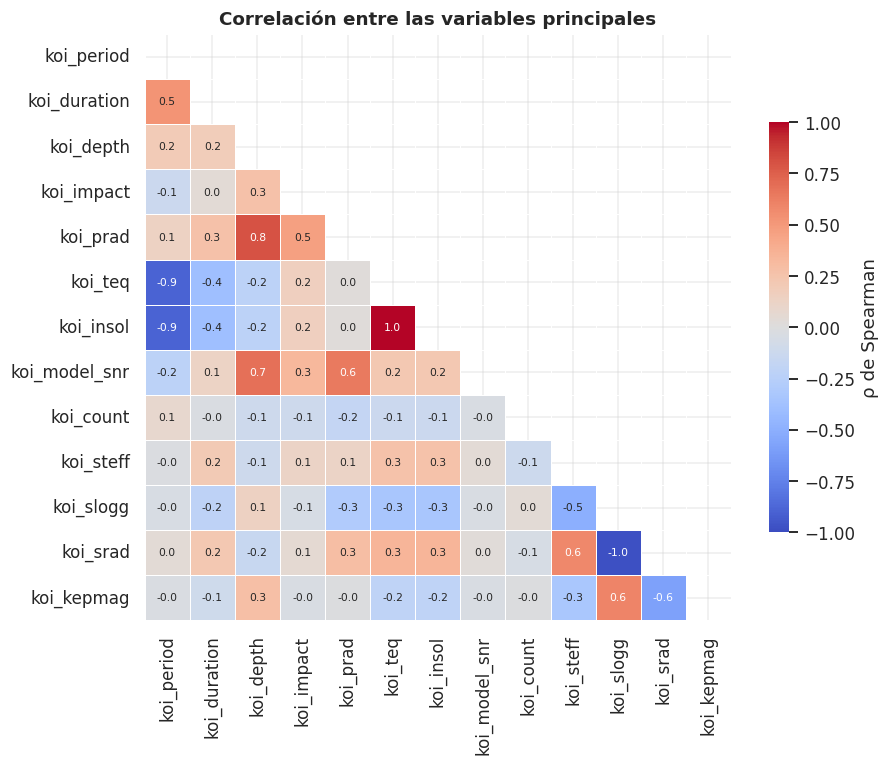

**Lectura.** Pares con correlación fuerte (|ρ| ≥ 0.8): `koi_teq` – `koi_insol` (+1.00); `koi_slogg` – `koi_srad` (-0.98); `koi_period` – `koi_teq` (-0.90); `koi_period` – `koi_insol` (-0.90); `koi_depth` – `koi_prad` (+0.80). Son variables que **repiten información**, algo a tener en cuenta al elegir las variables del modelo.

In [8]:
VARS_CORR = [c for c in ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_prad", "koi_teq",
                         "koi_insol", "koi_model_snr", "koi_count", "koi_steff", "koi_slogg", "koi_srad",
                         "koi_kepmag"] if c in df.columns]
corr = df[VARS_CORR].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="coolwarm", vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, square=True, linewidths=0.4,
            cbar_kws={"shrink": 0.7, "label": "ρ de Spearman"}, ax=ax)
ax.set_title("Correlación entre las variables principales")
plt.tight_layout()
plt.show()

pares = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
fuertes = pares[pares.abs() >= 0.8].sort_values(key=np.abs, ascending=False)
md("**Lectura.** Pares con correlación fuerte (|ρ| ≥ 0.8): "
   + ("; ".join(f"`{a}` – `{b}` ({r:+.2f})" for (a, b), r in fuertes.items()) if len(fuertes) else "ninguno")
   + ". Son variables que **repiten información**, algo a tener en cuenta al elegir las variables del modelo.")

## 8. Dos vistas astronómicas

**Izquierda:** el diagrama periodo-radio, el «mapa» clásico de los exoplanetas. **Derecha:** el porcentaje de falsos positivos según cuántas señales tiene la estrella. Cuando una estrella muestra varias señales, casi siempre son planetas reales, porque es muy improbable que varias falsas alarmas coincidan en la misma estrella (Lissauer et al., 2012).

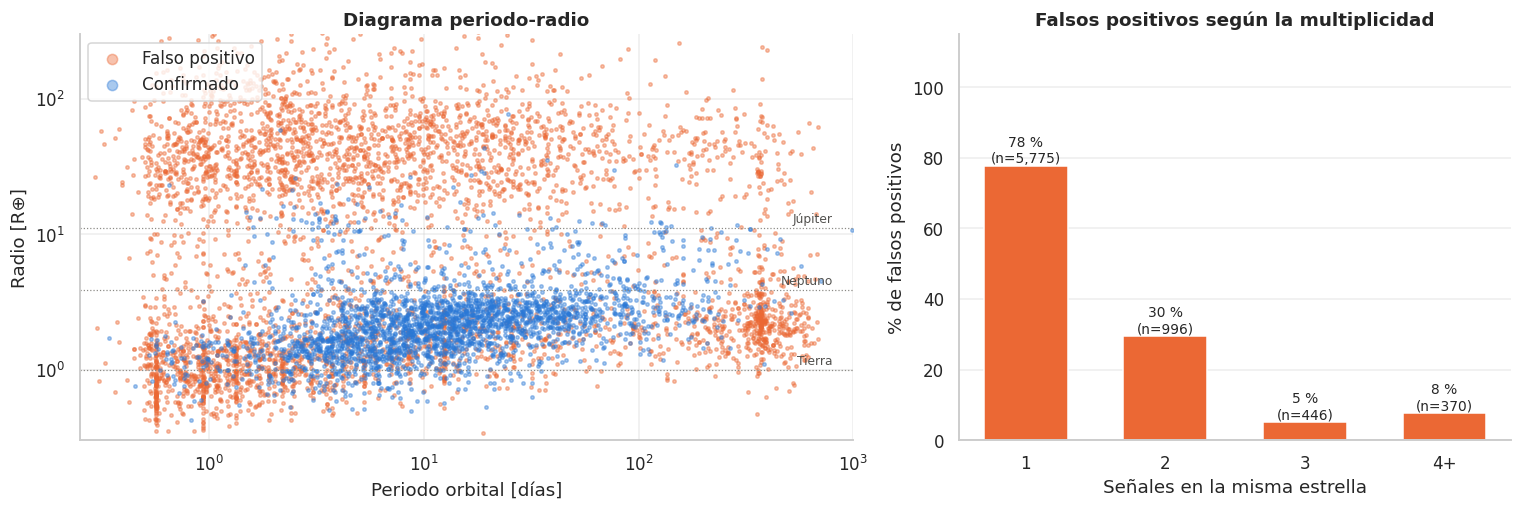

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
for clase in [FP, CONF]:
    sub = df[(df["koi_disposition"] == clase) & (df["koi_prad"] > 0) & (df["koi_period"] > 0)]
    ax.scatter(sub["koi_period"], sub["koi_prad"], s=5, alpha=0.4, color=COLORES[clase],
               label=ETIQUETA[clase], rasterized=True)
for r, nombre in [(1, "Tierra"), (3.9, "Neptuno"), (11.2, "Júpiter")]:
    ax.axhline(r, color=GRIS, lw=0.8, ls=":")
    ax.text(800, r * 1.08, nombre, color="#52514e", fontsize=8, ha="right")
ax.set(xscale="log", yscale="log", xlim=(0.25, 1000), ylim=(0.3, 300),
       xlabel="Periodo orbital [días]", ylabel="Radio [R⊕]", title="Diagrama periodo-radio")
ax.legend(markerscale=3, frameon=True, loc="upper left")

ax = axes[1]
cnt = lab[["koi_count", "es_planeta"]].dropna()
grupo = pd.cut(cnt["koi_count"], [0, 1, 2, 3, np.inf], labels=["1", "2", "3", "4+"])
tasa = cnt.groupby(grupo, observed=True)["es_planeta"].agg(n="size", fp=lambda s: 1 - s.mean())
barras = ax.bar(tasa.index.astype(str), tasa["fp"] * 100, color=COLORES[FP], width=0.6)
for b, (n, t) in zip(barras, tasa[["n", "fp"]].values):
    ax.text(b.get_x() + b.get_width() / 2, t * 100, f"{t * 100:.0f} %\n(n={int(n):,})", ha="center", va="bottom", fontsize=9)
ax.set(ylim=(0, 115), xlabel="Señales en la misma estrella", ylabel="% de falsos positivos",
       title="Falsos positivos según la multiplicidad")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 9. Cuidado: columnas que ya contienen la respuesta

Algunas columnas son el **resultado** del proceso que decide si una señal es un planeta, así que usarlas para predecirlo sería hacer trampa (*data leakage*): el modelo acertaría casi siempre y no serviría para nada. La tabla lo muestra con reglas de una línea, sin ningún modelo. Estas columnas se excluirán al modelar.

In [10]:
reglas = {
    "Tiene nombre «Kepler-…» (kepler_name)": lab["kepler_name"].notna() if "kepler_name" in lab else None,
    "koi_pdisposition = CANDIDATE": lab["koi_pdisposition"].eq(CAND) if "koi_pdisposition" in lab else None,
    "koi_score ≥ 0.5": lab["koi_score"].ge(0.5) if "koi_score" in lab else None,
    "Ninguna bandera koi_fpflag_* activa": lab.filter(like="koi_fpflag_").fillna(0).sum(axis=1).eq(0),
}
tabla_fuga = pd.DataFrame(
    [{"regla «→ es planeta»": k, "aciertos": pct((v.astype(int) == y_lab).mean())}
     for k, v in reglas.items() if v is not None])
print(f"Referencia: decir siempre «falso positivo» acierta el {pct(1 - y_lab.mean())}")
tabla_fuga

Referencia: decir siempre «falso positivo» acierta el 63.8 %


,regla «→ es planeta»,aciertos
0,Tiene nombre «Kepler-…» (kepler_name),99.9 %
1,koi_pdisposition = CANDIDATE,99.9 %
2,koi_score ≥ 0.5,97.3 %
3,Ninguna bandera koi_fpflag_* activa,98.5 %


## 10. Resumen: ¿qué ofrece este dataset?

La celda siguiente reúne las cifras clave del dataset en una sola tabla, a modo de ficha de presentación.

In [11]:
n_err = int(df.columns.str.contains(r"_err[12]$").sum())
ficha_dataset = pd.Series({
    "Fuente": "NASA Exoplanet Archive · tabla KOI Cumulative (API TAP)",
    "Fecha de descarga": meta["fecha_descarga_utc"],
    "Filas (señales / KOI)": f"{n_filas:,}",
    "Estrellas distintas": f"{df['kepid'].nunique():,}",
    "Columnas": f"{n_cols} ({n_err} son incertidumbres _err1/_err2)",
    "Columnas vacías o constantes": len(cols_vacias) + len(cols_constantes),
    "Variable objetivo": "koi_disposition (CONFIRMED / FALSE POSITIVE / CANDIDATE)",
    "Ejemplos con etiqueta": f"{len(lab):,} ({pct(y_lab.mean())} planetas)",
    "Candidatos por clasificar": f"{conteo[CAND]:,}",
    "Columnas con fuga a excluir": "kepler_name, koi_pdisposition, koi_score, koi_fpflag_*",
}, name="valor").to_frame()
ficha_dataset

,valor
Fuente,NASA Exoplanet Archive · tabla KOI Cumulative ...
Fecha de descarga,2026-11-08T19:18:22+00:00
Filas (señales / KOI),"9,564"
Estrellas distintas,"8,214"
Columnas,153 (46 son incertidumbres _err1/_err2)
Columnas vacías o constantes,35
Variable objetivo,koi_disposition (CONFIRMED / FALSE POSITIVE / ...
Ejemplos con etiqueta,"7,587 (36.2 % planetas)"
Candidatos por clasificar,"1,977"
Columnas con fuga a excluir,"kepler_name, koi_pdisposition, koi_score, koi_..."


### Conclusiones y siguientes pasos

El catálogo KOI es un buen dataset para un proyecto completo de ciencia de datos: tiene **miles de ejemplos y más de cien columnas** de naturaleza variada (geometría del tránsito, propiedades de la estrella, fotometría), una **variable objetivo clara** con un conjunto real de casos sin resolver (los candidatos), y suficientes retos para practicar: valores faltantes, variables con colas largas, variables redundantes y columnas que filtran la respuesta.

A simple vista, las variables relacionadas con el **tamaño de la señal** (profundidad y radio) y la **multiplicidad del sistema** son las que más diferencian a los planetas de los falsos positivos.

**Siguiente entrega:** limpieza y preparación de los datos (eliminar columnas vacías, constantes y con fuga, tratar los faltantes y aplicar transformaciones logarítmicas), seguida de los primeros modelos de clasificación.

### Referencias

- Akeson, R. L., et al. (2013). The NASA Exoplanet Archive: Data and tools for exoplanet research. *PASP, 125*(930), 989–999.
- Borucki, W. J., et al. (2010). Kepler planet-detection mission: Introduction and first results. *Science, 327*(5968), 977–980.
- Lissauer, J. J., et al. (2012). Almost all of Kepler's multiple-planet candidates are planets. *The Astrophysical Journal, 750*(2), 112.
- Thompson, S. E., et al. (2018). Planetary candidates observed by Kepler. VIII. A fully automated catalog with measured completeness and reliability based on Data Release 25. *ApJS, 235*(2), 38.
- NASA Exoplanet Archive. *KOI table (cumulative): column definitions*. https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html